# Descarte Fácil — previsão de demanda de remoção de grandes objetos

**Pergunta:** é possível prever a quantidade de solicitações de remoção de grandes objetos por subprefeitura e mês, usando o histórico público do SP156?

**Fonte:** Portal de Dados Abertos da Prefeitura de São Paulo — Dados do SP156.
O conjunto é atualizado periodicamente e contém solicitações registradas pelos canais SP156.
Consulte a página oficial e o dicionário antes de cada execução:
https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156

> Importante: o SP156 registra solicitações, não todos os descartes irregulares existentes.
> Portanto, o modelo prevê demanda registrada, e não mede diretamente a quantidade real de lixo nas ruas.


In [ ]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn xgboost requests

In [2]:
import io, requests, pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid
from xgboost import XGBRegressor

# CSV oficial mais recente identificado no portal (3º trimestre de 2026).
# Se a Prefeitura alterar o endereço, obtenha o novo link na página do conjunto.
DATA_URL = "https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource/f67fcc12-8da4-485f-92a3-d2af40cc771e/download/arquivo-final-3-trim-26.csv"
r = requests.get(DATA_URL, timeout=180)
r.raise_for_status()
raw = pd.read_csv(io.BytesIO(r.content), sep=None, engine="python", encoding_errors="replace")
print(raw.shape)
display(raw.head())
print(raw.columns.tolist())

(484232, 15)


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,07/01/2026,07/25/2026,PORTAL,Animais,Registro de animais - RGA,Registro Geral do Animal (RGA) - Solicitar ide...,Finalizada,SMS-DVZ-COSAP-Ermelino Matarazzo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,07/01/2026,07/25/2026,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Ermelino Matarazzo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,07/01/2026,NaN,CRM,Rua e bairro,Poluição Sonora - PSIU,Reclamação de poluição sonora - PSIU,Aberto,INTEGRACAO-SGF,Rua Oscar Freire,1800.0,5409011.0,-23.556617,-46.674384,PINHEIROS,JARDIM PAULISTA
3,07/01/2026,10/01/2026,MOBILE,Meio Ambiente,Árvore,Árvore – Solicitar avaliação em calçadas e pra...,Finalizada,INTEGRAÇÃO-SMGI/SGZ,Rua Leopoldo de Passos Lima,904.0,5271000.0,-23.428124,-46.795565,PERUS-ANHANGUERA,ANHANGUERA
4,07/01/2026,10/01/2026,MOBILE,Meio Ambiente,Árvore,Árvore – Solicitar avaliação em calçadas e pra...,Finalizada,INTEGRAÇÃO-SMGI/SGZ,Rua Leopoldo de Passos Lima,904.0,5271000.0,-23.428124,-46.795565,PERUS-ANHANGUERA,ANHANGUERA


['Data de Abertura', 'Data de Finalização', 'Meio de Comunicação', 'Tema', 'Assunto', 'Serviço', 'Status', 'Órgão', 'Logradouro', 'Número', 'CEP', 'Latitude', 'Longitude', 'Prefeitura Operacional', 'Distrito']


## 1. Preparação e seleção do serviço
Identifique as colunas de data, serviço/assunto e subprefeitura. Como os nomes podem variar entre extrações, confira `raw.columns` e ajuste o mapeamento abaixo conforme o dicionário oficial.

In [3]:
# AJUSTE estes nomes após inspecionar raw.columns e o dicionário oficial.
# O código tenta reconhecer nomes comuns, mas não substitui a conferência manual.
def find_col(columns, candidates):
    norm = {str(c).strip().lower(): c for c in columns}
    for cand in candidates:
        for k, original in norm.items():
            if cand in k:
                return original
    return None

date_col = find_col(raw.columns, ["data_abertura", "data de abertura", "data_solicitacao", "data da solicitação", "data"])
service_col = find_col(raw.columns, ["servico", "serviço", "assunto", "tema"])
district_col = find_col(raw.columns, ["subprefeitura", "distrito"])

print("Data:", date_col, "| Serviço/assunto:", service_col, "| Região:", district_col)
if date_col is None or service_col is None or district_col is None:
    raise ValueError("Mapeie manualmente date_col, service_col e district_col conforme as colunas impressas e o dicionário.")


Data: Data de Abertura | Serviço/assunto: Serviço | Região: Distrito


In [4]:
df = raw.copy()
df[date_col] = pd.to_datetime(df[date_col], errors="coerce", dayfirst=True)
df = df.dropna(subset=[date_col, district_col, service_col])

# Seleção inicial por termos relacionados a remoção de grandes objetos.
# Confira os valores únicos antes de fixar os termos; a nomenclatura muda ao longo do tempo.
print(df[service_col].astype(str).value_counts().head(40).to_string())


Serviço
Solicitar abordagem social a pessoa em situação de rua (SEAS)                                                           20319
Entulho e grandes objetos em via pública - solicitar remoção                                                            12109
Tapa-buraco                                                                                                              9701
Árvore – Solicitar avaliação em calçadas e praças para fins de poda ou remoção                                           6415
Reclamação de poluição sonora - PSIU                                                                                     5678
Solicitar remoção de veículo/carcaça abandonado na via pública                                                           4322
Fazer reclamação de falta de varrição                                                                                    4276
Reclamação                                                                                                    

## 2. Agregação temporal e variável-alvo
Após conferir a nomenclatura exibida acima, ajuste `TERMS` para selecionar apenas o serviço de remoção de grandes objetos. A unidade de análise será subprefeitura-mês; o alvo é o número de solicitações naquele mês.

In [6]:
TERMS = ["entulho e grandes objetos", "remoção de grandes objetos", "remocao de grandes objetos"]
service_text = df[service_col].astype(str).str.lower()
selected = df[service_text.apply(lambda x: any(t in x for t in TERMS))].copy()
if selected.empty:
    raise ValueError("Nenhum registro encontrado. Ajuste TERMS com o nome exato exibido em value_counts().")

selected["mes"] = selected[date_col].dt.to_period("M").dt.to_timestamp()
agg = (selected.groupby([district_col, "mes"]).size()
       .rename("solicitacoes").reset_index()
       .rename(columns={district_col:"regiao"}))
# Painel balanceado: meses sem solicitação observada recebem zero.
regions = agg["regiao"].dropna().unique()
months = pd.date_range(agg["mes"].min(), agg["mes"].max(), freq="MS")
panel = pd.MultiIndex.from_product([regions, months], names=["regiao","mes"]).to_frame(index=False)
panel = panel.merge(agg, on=["regiao","mes"], how="left")
panel["solicitacoes"] = panel["solicitacoes"].fillna(0).astype(int)
display(panel.head())
print("Período:", panel.mes.min(), "a", panel.mes.max(), "| linhas:", len(panel))

,regiao,mes,solicitacoes
0,AGUA RASA,2026-01-01,5
1,AGUA RASA,2026-02-01,4
2,AGUA RASA,2026-03-01,5
3,AGUA RASA,2026-04-01,4
4,AGUA RASA,2026-05-01,2


Período: 2026-01-01 00:00:00 a 2026-12-01 00:00:00 | linhas: 1152


## 3. Engenharia de atributos e divisão treino/teste
Usamos calendário e histórico defasado. A divisão é cronológica para evitar que meses futuros contaminem o treinamento. O teste corresponde aos 20% finais dos meses disponíveis.

In [11]:
panel = panel.sort_values(["regiao","mes"]).copy()
panel["ano"] = panel["mes"].dt.year
panel["mes_num"] = panel["mes"].dt.month
panel["trimestre"] = panel["mes"].dt.quarter

# Removemos colunas residuais de lag antigos para não afetar o dropna
cols_to_drop = [c for c in ["lag_6", "lag_12", "media_movel_3"] if c in panel.columns]
if cols_to_drop:
    panel = panel.drop(columns=cols_to_drop)

# Criamos apenas as defasagens curtas suportadas por 1 ano de dados
for lag in [1, 2, 3]:
    panel[f"lag_{lag}"] = panel.groupby("regiao")["solicitacoes"].shift(lag)
panel["media_movel_2"] = panel.groupby("regiao")["solicitacoes"].transform(lambda s: s.shift(1).rolling(2).mean())

model_df = panel.dropna().copy()
X = pd.get_dummies(model_df[["regiao","ano","mes_num","trimestre","lag_1","lag_2","lag_3","media_movel_2"]], columns=["regiao"], drop_first=False)
y = model_df["solicitacoes"]

cutoff = model_df["mes"].sort_values().unique()[int(len(model_df["mes"].unique())*0.8)]
train_mask = model_df["mes"] < cutoff
test_mask = model_df["mes"] >= cutoff
X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
print("Corte:", cutoff, "| treino:", len(X_train), "| teste:", len(X_test))

Corte: 2026-11-01 00:00:00 | treino: 672 | teste: 192


## 4. Treinamento e comparação de hiperparâmetros
Comparamos uma linha de base (previsão igual ao mês anterior), Random Forest e XGBoost. Métricas: MAE, RMSE e R². O MAE é especialmente interpretável: erro médio em número de solicitações.

In [12]:
results, fitted = [], {}
baseline = model_df.loc[test_mask, "lag_1"].values
results.append({"modelo":"Baseline lag-1", "MAE":mean_absolute_error(y_test, baseline),
                "RMSE":mean_squared_error(y_test, baseline)**0.5, "R2":r2_score(y_test, baseline)})

rf_grid = list(ParameterGrid({"n_estimators":[200,400], "max_depth":[8,None], "min_samples_leaf":[1,3]}))
best_rf, best_rf_mae = None, float("inf")
for params in rf_grid:
    m = RandomForestRegressor(random_state=42, n_jobs=-1, **params)
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    if mae < best_rf_mae: best_rf, best_rf_mae = (m, params), mae
rf = best_rf[0]; fitted["Random Forest"] = rf
pred = rf.predict(X_test)
results.append({"modelo":f"Random Forest {best_rf[1]}", "MAE":mean_absolute_error(y_test,pred),
                "RMSE":mean_squared_error(y_test,pred)**0.5, "R2":r2_score(y_test,pred)})

xgb_grid = list(ParameterGrid({"n_estimators":[200,400], "max_depth":[3,5], "learning_rate":[0.03,0.08]}))
best_xgb, best_xgb_mae = None, float("inf")
for params in xgb_grid:
    m = XGBRegressor(random_state=42, objective="reg:squarederror", n_jobs=-1, **params)
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    if mae < best_xgb_mae: best_xgb, best_xgb_mae = (m, params), mae
xgb = best_xgb[0]; fitted["XGBoost"] = xgb
pred = xgb.predict(X_test)
results.append({"modelo":f"XGBoost {best_xgb[1]}", "MAE":mean_absolute_error(y_test,pred),
                "RMSE":mean_squared_error(y_test,pred)**0.5, "R2":r2_score(y_test,pred)})

metrics = pd.DataFrame(results).sort_values("MAE")
display(metrics)


,modelo,MAE,RMSE,R2
1,"Random Forest {'max_depth': 8, 'min_samples_le...",3.872529,6.608171,0.604536
2,"XGBoost {'learning_rate': 0.03, 'max_depth': 3...",4.069690,6.495967,0.617851
0,Baseline lag-1,4.812500,8.645206,0.323145


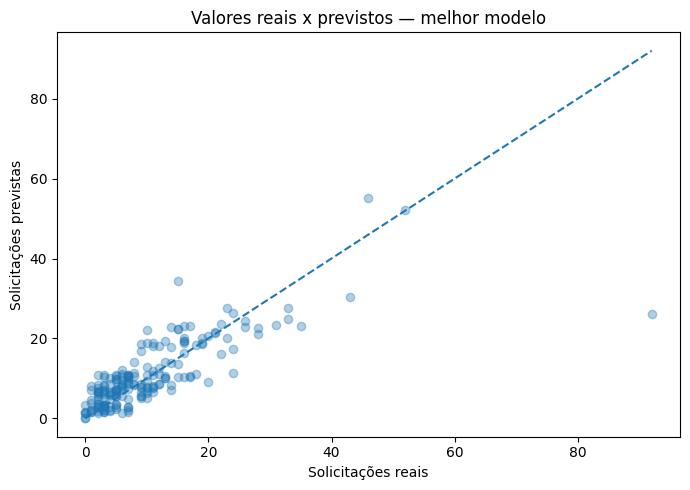

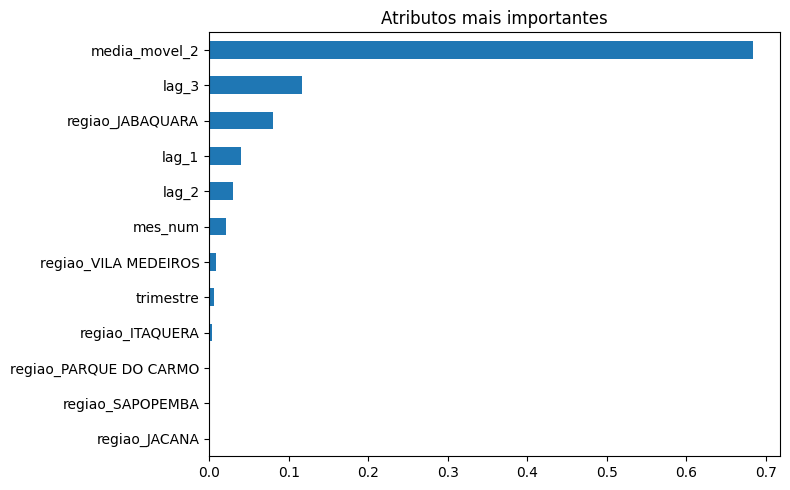

In [13]:
best_name = metrics.iloc[0]["modelo"]
best_model = fitted["Random Forest"] if best_name.startswith("Random Forest") else fitted["XGBoost"]
best_pred = best_model.predict(X_test)
plt.figure(figsize=(7,5))
plt.scatter(y_test, best_pred, alpha=.35)
lim = max(float(y_test.max()), float(np.max(best_pred)))
plt.plot([0,lim],[0,lim],"--")
plt.xlabel("Solicitações reais"); plt.ylabel("Solicitações previstas")
plt.title("Valores reais x previstos — melhor modelo")
plt.tight_layout(); plt.show()

if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values().tail(12)
    imp.plot(kind="barh", figsize=(8,5), title="Atributos mais importantes")
    plt.tight_layout(); plt.show()


## 5. Interpretação para o cidadão

Preencha a conclusão com os resultados efetivamente obtidos após executar todas as células:
- Melhor modelo e hiperparâmetros: **[preencher a partir da tabela]**.
- MAE no teste: **[preencher]** solicitações por subprefeitura/mês.
- RMSE e R²: **[preencher]**.
- Atributos mais relevantes: **[preencher a partir do gráfico]**.

**Aplicação no Descarte Fácil:** a previsão pode apoiar a priorização de comunicação e planejamento de coleta em regiões com demanda historicamente elevada. O app pode usar a informação como indicador de contexto, sem afirmar que uma região terá descarte irregular com certeza.

**Limitações:** solicitações SP156 dependem de conhecimento e iniciativa do cidadão; não representam todos os descartes. O recorte por subprefeitura é menos preciso que o CEP/rua. Mudanças de nomenclatura, cobertura e políticas públicas podem afetar o padrão. Uma previsão agregada não determina o dia exato em que o caminhão passará.
